
# FraudShield AI
## Baseline Fraud Detection Model

### Objective
Train a LightGBM classifier to detect fraudulent transactions.

### Evaluation strategy
- Chronological 80/20 train-validation split
- Average Precision and ROC-AUC for ranking performance
- Precision, Recall, and F1-score at multiple thresholds
- Confusion matrix for classification errors

The validation set represents later transactions and will be used for model evaluation and threshold analysis.


In [1]:

from pathlib import Path
import json
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

PROJECT_ROOT = Path(r"D:\FraudShield")
DATA_FILE = PROJECT_ROOT / "data" / "processed" / "train_merged.parquet"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_FILE)

print("Dataset shape:", df.shape)
print(f"Fraud rate: {df['isFraud'].mean() * 100:.4f}%")


Dataset shape: (590540, 434)
Fraud rate: 3.4990%


In [2]:

TARGET = "isFraud"
TIME_COLUMN = "TransactionDT"
VALIDATION_FRACTION = 0.20
RANDOM_STATE = 42

df = df.sort_values(TIME_COLUMN).reset_index(drop=True)

split_index = int(len(df) * (1 - VALIDATION_FRACTION))

train_df = df.iloc[:split_index].copy()
valid_df = df.iloc[split_index:].copy()

y_train = train_df[TARGET].astype("int8")
y_valid = valid_df[TARGET].astype("int8")

feature_columns = [
    col for col in df.columns
    if col not in [TARGET, "TransactionID"]
]

X_train = train_df[feature_columns].copy()
X_valid = valid_df[feature_columns].copy()

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Number of features:", len(feature_columns))
print(f"Training fraud rate: {y_train.mean() * 100:.4f}%")
print(f"Validation fraud rate: {y_valid.mean() * 100:.4f}%")


Training rows: 472432
Validation rows: 118108
Number of features: 432
Training fraud rate: 3.5135%
Validation fraud rate: 3.4409%


In [3]:

categorical_columns = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in categorical_columns:
    train_values = X_train[col].astype("string").fillna("__MISSING__")
    valid_values = X_valid[col].astype("string").fillna("__MISSING__")

    categories = pd.Index(
        pd.concat([train_values, valid_values], ignore_index=True).unique()
    )

    X_train[col] = pd.Categorical(
        train_values, categories=categories
    )
    X_valid[col] = pd.Categorical(
        valid_values, categories=categories
    )

positive_count = int(y_train.sum())
negative_count = len(y_train) - positive_count
scale_pos_weight = negative_count / max(positive_count, 1)

print("Categorical features:", len(categorical_columns))
print(f"Positive class weight: {scale_pos_weight:.2f}")


Categorical features: 31
Positive class weight: 27.46


In [4]:

model = lgb.LGBMClassifier(
    objective="binary",
    metric="None",
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbosity=-1,
)

model.fit(
    X_train,
    y_train,
    categorical_feature=categorical_columns,
    eval_set=[(X_valid, y_valid)],
    eval_metric="average_precision",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=100,
            first_metric_only=True,
        ),
        lgb.log_evaluation(period=100),
    ],
)

print("Best iteration:", model.best_iteration_)


d:\FraudShield\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's average_precision: 0.481235
[200]	valid_0's average_precision: 0.503812
[300]	valid_0's average_precision: 0.514342
[400]	valid_0's average_precision: 0.523569
[500]	valid_0's average_precision: 0.526808
[600]	valid_0's average_precision: 0.53107
[700]	valid_0's average_precision: 0.533831
[800]	valid_0's average_precision: 0.535333
Early stopping, best iteration is:
[786]	valid_0's average_precision: 0.53547
Evaluated only: average_precision
Best iteration: 786


In [5]:

probabilities = model.predict_proba(
    X_valid,
    num_iteration=model.best_iteration_,
)[:, 1]

print(f"Average Precision: {average_precision_score(y_valid, probabilities):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_valid, probabilities):.4f}")

threshold_rows = []

for threshold in [0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.50]:
    predictions = (probabilities >= threshold).astype("int8")

    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(
            y_valid, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_valid, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_valid, predictions, zero_division=0
        ),
        "transactions_flagged": int(predictions.sum()),
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))


Average Precision: 0.5355
ROC-AUC: 0.9058


,threshold,precision,recall,f1,transactions_flagged
0,0.01,0.0391,0.9916,0.0752,103139
1,0.02,0.0435,0.9811,0.0834,91565
2,0.05,0.0571,0.9594,0.1078,68297
3,0.10,0.0785,0.9213,0.1447,47702
4,0.20,0.1242,0.8637,0.2171,28272
5,0.30,0.1736,0.7995,0.2852,18719
6,0.50,0.2947,0.6912,0.4132,9531


In [6]:

import joblib

predictions_050 = (probabilities >= 0.50).astype("int8")

metrics = {
    "train_rows": int(len(X_train)),
    "validation_rows": int(len(X_valid)),
    "feature_count": int(len(feature_columns)),
    "best_iteration": int(model.best_iteration_ or 0),
    "average_precision": float(
        average_precision_score(y_valid, probabilities)
    ),
    "roc_auc": float(roc_auc_score(y_valid, probabilities)),
    "precision_at_050": float(
        precision_score(y_valid, predictions_050, zero_division=0)
    ),
    "recall_at_050": float(
        recall_score(y_valid, predictions_050, zero_division=0)
    ),
    "f1_at_050": float(
        f1_score(y_valid, predictions_050, zero_division=0)
    ),
    "confusion_matrix_at_050": confusion_matrix(
        y_valid, predictions_050, labels=[0, 1]
    ).tolist(),
}

joblib.dump(model, MODEL_DIR / "lightgbm_baseline.joblib")
threshold_results.to_csv(
    REPORT_DIR / "threshold_comparison.csv", index=False
)

with open(REPORT_DIR / "baseline_metrics.json", "w") as file:
    json.dump(metrics, file, indent=2)

with open(MODEL_DIR / "feature_columns.json", "w") as file:
    json.dump(feature_columns, file, indent=2)

display(pd.Series(metrics, name="value").to_frame())

print("Model and reports saved successfully.")


,value
train_rows,472432
validation_rows,118108
feature_count,432
best_iteration,786
average_precision,0.53547
roc_auc,0.905843
precision_at_050,0.294722
recall_at_050,0.691191
f1_at_050,0.41324
confusion_matrix_at_050,"[[107322, 6722], [1255, 2809]]"


Model and reports saved successfully.


In [7]:

importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": model.feature_importances_,
}).sort_values("importance", ascending=False)

display(importance.head(25))

importance.to_csv(
    REPORT_DIR / "lightgbm_feature_importance.csv",
    index=False
)

,feature,importance
13,P_emaildomain,1408
3,card1,1139
4,card2,1108
431,DeviceInfo,1051
422,id_31,998
9,addr1,977
0,TransactionDT,841
1,TransactionAmt,835
27,C13,563
421,id_30,530


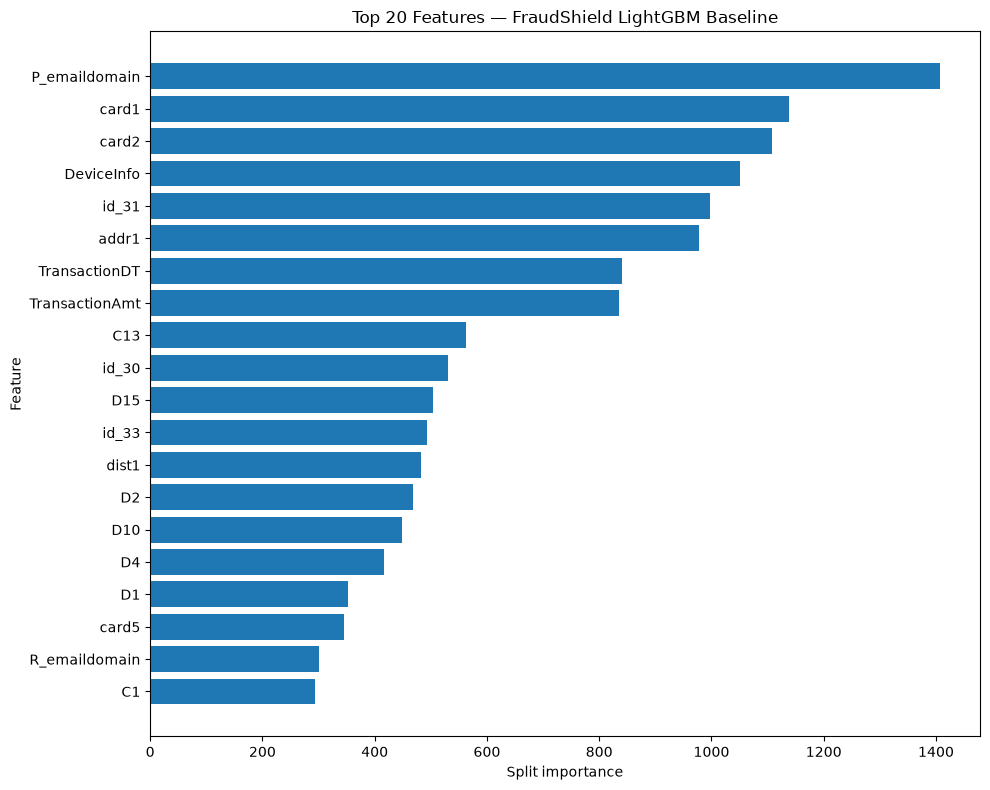

In [8]:

top_features = importance.head(20).sort_values("importance")

plt.figure(figsize=(10, 8))
plt.barh(
    top_features["feature"],
    top_features["importance"]
)
plt.xlabel("Split importance")
plt.ylabel("Feature")
plt.title("Top 20 Features — FraudShield LightGBM Baseline")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "lightgbm_feature_importance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()